# 11 — Submission Optimization

## Hipotez ve seçim protokolü

`09` modelinin known-TWS kolu güçlüdür; `10` explainability çalışması asıl zayıflığın masked-TWS kolu olduğunu göstermiştir. Bu notebook known uzmanı ve deployment-benzeri temporal validation'ı sabit tutar. Masked uzman için aşağıdaki hipotezler test edilir:

1. Yalnız mevcut covariate etkileşimleri küçük katkı sağlayabilir.
2. Aynı konumun **yalnız geçmiş target gözlemlerinden** üretilmiş persistence ve seasonal climatology priors'ları, kayıp `TWS_t` bilgisini kısmen telafi edebilir.
3. Bu priors doğrudan tahmin olarak veya LightGBM'e ek feature olarak kullanılabilir.
4. Baseline'ı geçmeyen hiçbir yöntem final submission'a alınmaz.

Mevcut public leaderboard referansı: **0.835133802**. Test target'ı hiçbir aşamada kullanılmaz.

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import root_mean_squared_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
SEED=42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",100)

def find_root(start=None):
    p=Path(start or Path.cwd()).resolve()
    for c in [p,*p.parents]:
        if (c/"data"/"raw"/"Train.csv").exists(): return c
    raise FileNotFoundError("Repository root bulunamadı")

ROOT=find_root(); DATA=ROOT/"data"/"raw"; OUT=ROOT/"submissions"
print("ROOT:",ROOT)

ROOT: C:\global-water-storage-forecasting


## 1. `09` baseline'ının birebir kurulması

In [2]:
train=pd.read_csv(DATA/"Train.csv",parse_dates=["time"])
test=pd.read_csv(DATA/"Test.csv",parse_dates=["time"])
sample=pd.read_csv(DATA/"SampleSubmission.csv")
test["_original_order"]=np.arange(len(test))
assert train.sample_id.is_unique and test.ID.is_unique and sample.ID.is_unique
assert test.ID.equals(sample.ID)
print(train.shape,test.shape,"masked share",test.TWS_t.isna().mean())

(2154021, 13) (280961, 14) masked share 0.6652631504016572


In [3]:
SPEI=["SPEI_01_t","SPEI_03_t","SPEI_06_t","SPEI_12_t"]

def build_static_features(df):
    o=df.copy(); dt=pd.to_datetime(o.time)
    o["month"]=dt.dt.month.astype("int8"); o["quarter"]=dt.dt.quarter.astype("int8")
    o["year"]=dt.dt.year.astype("int16")
    o["elapsed_month"]=((dt.dt.year-train.time.dt.year.min())*12+dt.dt.month-1).astype("int16")
    o["month_sin_calc"]=np.sin(2*np.pi*o.month/12); o["month_cos_calc"]=np.cos(2*np.pi*o.month/12)
    o["season_sin"]=np.sin(2*np.pi*o.quarter/4); o["season_cos"]=np.cos(2*np.pi*o.quarter/4)
    s=o[SPEI]; o["spei_mean"]=s.mean(axis=1); o["spei_min"]=s.min(axis=1)
    o["spei_max"]=s.max(axis=1); o["spei_std"]=s.std(axis=1)
    o["spei_01_minus_12"]=o.SPEI_01_t-o.SPEI_12_t
    o["spei_03_minus_12"]=o.SPEI_03_t-o.SPEI_12_t
    o["spei_short_long_ratio"]=o.SPEI_01_t/(o.SPEI_12_t.abs()+.1)
    o["lat_band_5"]=np.floor((o.lat+90)/5); o["lon_band_5"]=np.floor((o.lon+180)/5)
    o["spatial_bin_10"]=o.lat_band_5*100+o.lon_band_5
    o["lat_lon_interaction"]=o.lat*o.lon/1000
    o["lat_sin"]=np.sin(np.radians(o.lat)); o["lat_cos"]=np.cos(np.radians(o.lat))
    o["lon_sin"]=np.sin(np.radians(o.lon)); o["lon_cos"]=np.cos(np.radians(o.lon))
    # 10/önceki residual bulgularından türetilen, target kullanmayan etkileşimler.
    o["soil_x_spei_mean"]=o.SOIL_MOISTURE_t*o.spei_mean
    o["soil_minus_spei_mean"]=o.SOIL_MOISTURE_t-o.spei_mean
    o["spei_01_x_12"]=o.SPEI_01_t*o.SPEI_12_t
    o["drought_severity"]=(-o[SPEI].clip(upper=0)).mean(axis=1)
    return o

train_f=build_static_features(train); test_f=build_static_features(test)
A=["lat","lon","TWS_t",*SPEI,"SOIL_MOISTURE_t","month","month_sin","month_cos","year"]
B=["quarter","elapsed_month","month_sin_calc","month_cos_calc","season_sin","season_cos"]
C=["spei_mean","spei_min","spei_max","spei_std","spei_01_minus_12","spei_03_minus_12","spei_short_long_ratio"]
D=["lat_band_5","lon_band_5","spatial_bin_10","lat_lon_interaction","lat_sin","lat_cos","lon_sin","lon_cos"]
BASE_FEATURES=list(dict.fromkeys(A+B+C+D))
BASE_MASKED=[c for c in BASE_FEATURES if c!="TWS_t"]
INTERACTIONS=["soil_x_spei_mean","soil_minus_spei_mean","spei_01_x_12","drought_severity"]
BASE_PARAMS=dict(n_estimators=160,learning_rate=.08,num_leaves=63,min_child_samples=100,
                 reg_lambda=1.0,subsample=.85,colsample_bytree=.9,
                 random_state=SEED,n_jobs=4,verbosity=-1)
print("09 features:",len(BASE_FEATURES),"masked:",len(BASE_MASKED))

09 features: 33 masked: 32


In [4]:
test_date_stats=test.groupby("time").agg(n=("ID","size"),known=("TWS_t","count"))
KNOWN_POS=set(np.flatnonzero(test_date_stats.known.to_numpy()>test_date_stats.n.to_numpy()*.5))

def create_temporal_splits(df,n_splits=3,block=18):
    dates=np.array(sorted(df.time.unique())); start=len(dates)-n_splits*block; out=[]
    for i in range(n_splits):
        vd=dates[start+i*block:start+(i+1)*block]; td=dates[:start+i*block]
        out.append((np.flatnonzero(df.time.isin(td)),np.flatnonzero(df.time.isin(vd))))
    return out

SPLITS=create_temporal_splits(train_f)[-2:]
def segment_mask(va):
    dates=np.array(sorted(va.time.unique()))
    return va.time.isin({d for j,d in enumerate(dates) if j in KNOWN_POS}).to_numpy()

folds=[]
for fold,(ti,vi) in enumerate(SPLITS,1):
    tr,va=train_f.iloc[ti].copy(),train_f.iloc[vi].copy()
    known=segment_mask(va)
    folds.append({"fold":fold,"train":tr,"valid":va,"known":known})
    print(fold,tr.time.min(),"→",tr.time.max(),"|",va.time.min(),"→",va.time.max(),
          "known/masked",known.sum(),(~known).sum())

1 2002-05-01 00:00:00 → 2011-05-01 00:00:00 | 2011-08-01 00:00:00 → 2013-07-01 00:00:00 known/masked 93511 187425


2 2002-05-01 00:00:00 → 2013-07-01 00:00:00 | 2013-11-01 00:00:00 → 2015-08-01 00:00:00 known/masked 93638 187424


## 2. Leakage-free historical priors

Feature'ların anlamı:

- `prior_last_target`: fold eğitim kesiminin konum bazında son target'ı.
- `prior_recent_mean`: konumun son 12 eğitim target'ının ortalaması.
- `prior_location_mean/std`: yalnız geçmiş dönemdeki uzun dönem konum seviyesi.
- `prior_location_month`: konum-ay climatology'si; az gözlemde konum ortalamasına shrink edilir.
- `prior_global_month`: ilgili ayın global geçmiş ortalaması.

Validation priors yalnız fold train'den hesaplanır. Model train satırlarında her satırın kendi target'ını görmesini engellemek için `shift(1)`, expanding/rolling kullanılır. Böylece target-derived feature kullanılır fakat leakage oluşmaz.

In [5]:
PRIOR_FEATURES=["prior_last_target","prior_recent_mean","prior_location_mean",
                "prior_location_std","prior_location_month","prior_global_month",
                "prior_age_months"]

def add_causal_train_priors(df):
    o=df.sort_values(["lat","lon","time"]).copy()
    g=o.groupby(["lat","lon"],sort=False)["target"]
    o["prior_last_target"]=g.shift(1)
    o["prior_recent_mean"]=(g.shift(1).groupby([o.lat,o.lon])
                             .rolling(12,min_periods=3).mean().reset_index(level=[0,1],drop=True))
    shifted=g.shift(1)
    o["prior_location_mean"]=shifted.groupby([o.lat,o.lon]).expanding().mean().reset_index(level=[0,1],drop=True)
    o["prior_location_std"]=shifted.groupby([o.lat,o.lon]).expanding().std().reset_index(level=[0,1],drop=True)
    o["prior_location_month"]=(shifted.groupby([o.lat,o.lon,o.month])
                                .expanding().mean().reset_index(level=[0,1,2],drop=True))
    o["prior_global_month"]=o.groupby("month")["target"].transform(lambda x:x.shift(1).expanding().mean())
    o["prior_age_months"]=1.0
    return o.sort_index()

def fit_prior_state(history):
    h=history.sort_values(["lat","lon","time"]).copy()
    loc=h.groupby(["lat","lon"]).target.agg(["mean","std","count"]).rename(
        columns={"mean":"prior_location_mean","std":"prior_location_std","count":"loc_count"})
    last=h.groupby(["lat","lon"]).tail(1).set_index(["lat","lon"])[["target","time"]].rename(
        columns={"target":"prior_last_target","time":"prior_last_time"})
    recent=(h.groupby(["lat","lon"],group_keys=False).tail(12)
              .groupby(["lat","lon"]).target.mean().rename("prior_recent_mean"))
    lm=h.groupby(["lat","lon","month"]).target.agg(["sum","count"]).rename(columns={"sum":"lm_sum","count":"lm_count"})
    gm=h.groupby("month").target.mean().rename("prior_global_month")
    return loc.join(last).join(recent),lm,gm

def apply_prior_state(df,state,alpha=4.0):
    loc,lm,gm=state; o=df.copy()
    o=o.join(loc,on=["lat","lon"]).join(lm,on=["lat","lon","month"]).join(gm,on="month")
    o["prior_location_month"]=(o.lm_sum+alpha*o.prior_location_mean)/(o.lm_count.fillna(0)+alpha)
    o["prior_age_months"]=((o.time.dt.year-o.prior_last_time.dt.year)*12+
                           o.time.dt.month-o.prior_last_time.dt.month).astype(float)
    return o.drop(columns=["loc_count","prior_last_time","lm_sum","lm_count"],errors="ignore")

prior_folds=[]
for f in folds:
    trp=add_causal_train_priors(f["train"])
    vap=apply_prior_state(f["valid"],fit_prior_state(f["train"]))
    prior_folds.append({**f,"train_prior":trp,"valid_prior":vap})
print("Prior columns ready:",PRIOR_FEATURES)

Prior columns ready: ['prior_last_target', 'prior_recent_mean', 'prior_location_mean', 'prior_location_std', 'prior_location_month', 'prior_global_month', 'prior_age_months']


## 3. Baseline ve kontrollü fikir deneyleri

In [6]:
def lgbm(params=None):
    p=BASE_PARAMS.copy()
    if params:p.update(params)
    return LGBMRegressor(**p)

def evaluate(method,features,use_priors=False,model_factory=None,direct_prior=None):
    known_parts=[]; masked_parts=[]; sec=0
    for raw,pf in zip(folds,prior_folds):
        tr=pf["train_prior"] if use_priors else raw["train"]
        va=pf["valid_prior"] if use_priors else raw["valid"]
        known=raw["known"]
        # Known expert her deneyde 09 ile birebir aynı.
        km=lgbm(); km.fit(raw["train"][BASE_FEATURES],raw["train"].target)
        kp=km.predict(raw["valid"].loc[known,BASE_FEATURES])
        known_parts.append(pd.DataFrame({"idx":raw["valid"].index[known],"target":raw["valid"].target.to_numpy()[known],"pred":kp}))
        if direct_prior:
            mp=va.loc[~known,direct_prior].to_numpy()
        else:
            model=(model_factory or lgbm)(); t0=perf_counter(); model.fit(tr[features],tr.target); sec+=perf_counter()-t0
            mp=model.predict(va.loc[~known,features])
        masked_parts.append(pd.DataFrame({"idx":raw["valid"].index[~known],"fold":raw["fold"],
                                          "target":raw["valid"].target.to_numpy()[~known],"pred":mp}))
    ko=pd.concat(known_parts,ignore_index=True); mo=pd.concat(masked_parts,ignore_index=True)
    all_oof=pd.concat([ko,mo],ignore_index=True)
    return {"method":method,"change":"","features":features,"use_priors":use_priors,
            "known_rmse":root_mean_squared_error(ko.target,ko.pred),
            "masked_rmse":root_mean_squared_error(mo.target,mo.pred),
            "overall_rmse":root_mean_squared_error(all_oof.target,all_oof.pred),
            "masked_oof":mo,"training_sec":sec}

experiments=[]
baseline=evaluate("09 baseline",BASE_MASKED)
baseline["change"]="No change"
experiments.append(baseline)

interaction=evaluate("Static interactions",BASE_MASKED+INTERACTIONS)
interaction["change"]="Soil-SPEI and drought interactions"
experiments.append(interaction)

for prior in ["prior_last_target","prior_recent_mean","prior_location_month"]:
    r=evaluate("Direct "+prior,[],use_priors=True,direct_prior=prior)
    r["change"]="Historical prior used directly"; experiments.append(r)

prior_sets={
    "LGBM + persistence priors":["prior_last_target","prior_recent_mean","prior_age_months"],
    "LGBM + climatology priors":["prior_location_mean","prior_location_std","prior_location_month","prior_global_month"],
    "LGBM + all priors":PRIOR_FEATURES,
    "LGBM + priors + interactions":PRIOR_FEATURES+INTERACTIONS,
}
for name,extra in prior_sets.items():
    r=evaluate(name,BASE_MASKED+extra,use_priors=True)
    r["change"]=", ".join(extra); experiments.append(r)

def results_frame(items):
    return pd.DataFrame([{"Experiment":r["method"],"What changed":r["change"],
      "Known RMSE":r["known_rmse"],"Masked RMSE":r["masked_rmse"],
      "Overall RMSE":r["overall_rmse"],"Difference vs baseline":baseline["overall_rmse"]-r["overall_rmse"],
      "Improved":r["overall_rmse"]<baseline["overall_rmse"],"Feature count":len(r["features"]),
      "Training sec":r["training_sec"]} for r in items]).sort_values("Overall RMSE")

display(results_frame(experiments))

,Experiment,What changed,Known RMSE,Masked RMSE,Overall RMSE,Difference vs baseline,Improved,Feature count,Training sec
0,09 baseline,No change,0.608198,0.761184,0.713889,0.000000,False,32,32.478211
1,Static interactions,Soil-SPEI and drought interactions,0.608198,0.763775,0.715732,-0.001843,False,36,36.696486
6,LGBM + climatology priors,"prior_location_mean, prior_location_std, prior...",0.608198,0.768158,0.718854,-0.004965,False,36,34.478202
7,LGBM + all priors,"prior_last_target, prior_recent_mean, prior_lo...",0.608198,0.831686,0.764553,-0.050664,False,39,38.866379
8,LGBM + priors + interactions,"prior_last_target, prior_recent_mean, prior_lo...",0.608198,0.839727,0.770393,-0.056505,False,43,18.756058
5,LGBM + persistence priors,"prior_last_target, prior_recent_mean, prior_ag...",0.608198,0.851254,0.778786,-0.064897,False,35,33.175775
3,Direct prior_recent_mean,Historical prior used directly,0.608198,0.959591,0.858696,-0.144807,False,0,0.000000
2,Direct prior_last_target,Historical prior used directly,0.608198,1.010775,0.897009,-0.183120,False,0,0.000000
4,Direct prior_location_month,Historical prior used directly,0.608198,1.085262,0.953289,-0.239401,False,0,0.000000


## 4. En iyi prior setinde küçük model/parametre araması

In [7]:
best_feature_result=min([r for r in experiments if r["features"]],key=lambda r:r["overall_rmse"])
SEARCH_FEATURES=best_feature_result["features"]
USE_PRIORS=best_feature_result["use_priors"]
print("Search base:",best_feature_result["method"],len(SEARCH_FEATURES),"priors",USE_PRIORS)

candidates=[
 ("LGBM regularized",lambda:lgbm(dict(n_estimators=240,learning_rate=.05,num_leaves=31,
    min_child_samples=160,reg_alpha=.2,reg_lambda=3.0))),
 ("LGBM flexible",lambda:lgbm(dict(n_estimators=220,learning_rate=.06,num_leaves=95,
    min_child_samples=120,reg_alpha=.1,reg_lambda=2.0))),
 ("XGBoost prior",lambda:XGBRegressor(n_estimators=180,learning_rate=.06,max_depth=7,min_child_weight=30,
    subsample=.85,colsample_bytree=.9,reg_alpha=.1,reg_lambda=2,tree_method="hist",random_state=SEED,n_jobs=4)),
 ("CatBoost prior",lambda:CatBoostRegressor(iterations=220,learning_rate=.07,depth=8,l2_leaf_reg=8,
    random_strength=.5,loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=4))
]
model_experiments=[]
for name,factory in candidates:
    r=evaluate(name,SEARCH_FEATURES,use_priors=USE_PRIORS,model_factory=factory)
    r["change"]="Same best features; different masked model"; experiments.append(r); model_experiments.append(r)
display(results_frame(model_experiments))

Search base: 09 baseline 32 priors False


,Experiment,What changed,Known RMSE,Masked RMSE,Overall RMSE,Difference vs baseline,Improved,Feature count,Training sec
1,LGBM flexible,Same best features; different masked model,0.608198,0.766267,0.717507,-0.003618,False,32,28.856702
0,LGBM regularized,Same best features; different masked model,0.608198,0.768968,0.719432,-0.005543,False,32,19.324211
3,CatBoost prior,Same best features; different masked model,0.608198,0.770076,0.720222,-0.006333,False,32,65.386776
2,XGBoost prior,Same best features; different masked model,0.608198,0.771975,0.721576,-0.007688,False,32,29.762718


## 5. OOF ensemble ve conservative prior blend

In [8]:
# Aynı masked OOF satırlarına kesin hizalama.
pool=sorted([r for r in experiments if "masked_oof" in r],key=lambda r:r["masked_rmse"])[:5]
base_ids=pool[0]["masked_oof"][["idx","fold","target"]].copy()
P=[]
for r in pool:
    z=base_ids[["idx"]].merge(r["masked_oof"][["idx","pred"]],on="idx",how="left")
    assert z.pred.notna().all(); P.append(z.pred.to_numpy())
P=np.column_stack(P); y=base_ids.target.to_numpy()

# İki en iyi yöntemin 0.05 grid blend'i; daha büyük arama overfit riskini artırır.
blend_rows=[]
for i in range(len(pool)):
    for j in range(i+1,len(pool)):
        for w in np.arange(0,1.001,.05):
            pred=w*P[:,i]+(1-w)*P[:,j]
            blend_rows.append({"i":i,"j":j,"w_i":w,"masked_rmse":root_mean_squared_error(y,pred)})
blends=pd.DataFrame(blend_rows).sort_values("masked_rmse")
display(blends.head(10))
b=blends.iloc[0]; ri,rj=pool[int(b.i)],pool[int(b.j)]
blend_pred=float(b.w_i)*P[:,int(b.i)]+(1-float(b.w_i))*P[:,int(b.j)]
blend_oof=base_ids.copy(); blend_oof["pred"]=blend_pred

# Known OOF ağırlığı sabit olduğundan overall metrik segment boyutlarıyla yeniden hesaplanır.
n_known=sum(f["known"].sum() for f in folds); n_masked=len(blend_oof)
blend_overall=np.sqrt((baseline["known_rmse"]**2*n_known+b.masked_rmse**2*n_masked)/(n_known+n_masked))
ensemble={"method":"OOF two-model blend","change":f'{b.w_i:.2f}*{ri["method"]} + {1-b.w_i:.2f}*{rj["method"]}',
          "features":ri["features"],"use_priors":ri["use_priors"],"known_rmse":baseline["known_rmse"],
          "masked_rmse":b.masked_rmse,"overall_rmse":blend_overall,"masked_oof":blend_oof,
          "training_sec":ri["training_sec"]+rj["training_sec"],"blend":(ri,rj,float(b.w_i))}
experiments.append(ensemble)
display(results_frame(experiments))

,i,j,w_i,masked_rmse
55,0,3,0.65,0.758030
54,0,3,0.60,0.758073
56,0,3,0.70,0.758111
53,0,3,0.55,0.758239
57,0,3,0.75,0.758315
52,0,3,0.50,0.758529
58,0,3,0.80,0.758643
51,0,3,0.45,0.758942
59,0,3,0.85,0.759094
117,1,3,0.60,0.759456


,Experiment,What changed,Known RMSE,Masked RMSE,Overall RMSE,Difference vs baseline,Improved,Feature count,Training sec
13,OOF two-model blend,0.65*09 baseline + 0.35*LGBM + climatology priors,0.608198,0.758030,0.711647,0.002241,True,32,66.956413
0,09 baseline,No change,0.608198,0.761184,0.713889,0.000000,False,32,32.478211
1,Static interactions,Soil-SPEI and drought interactions,0.608198,0.763775,0.715732,-0.001843,False,36,36.696486
10,LGBM flexible,Same best features; different masked model,0.608198,0.766267,0.717507,-0.003618,False,32,28.856702
6,LGBM + climatology priors,"prior_location_mean, prior_location_std, prior...",0.608198,0.768158,0.718854,-0.004965,False,36,34.478202
9,LGBM regularized,Same best features; different masked model,0.608198,0.768968,0.719432,-0.005543,False,32,19.324211
12,CatBoost prior,Same best features; different masked model,0.608198,0.770076,0.720222,-0.006333,False,32,65.386776
11,XGBoost prior,Same best features; different masked model,0.608198,0.771975,0.721576,-0.007688,False,32,29.762718
7,LGBM + all priors,"prior_last_target, prior_recent_mean, prior_lo...",0.608198,0.831686,0.764553,-0.050664,False,39,38.866379
8,LGBM + priors + interactions,"prior_last_target, prior_recent_mean, prior_lo...",0.608198,0.839727,0.770393,-0.056505,False,43,18.756058


## 6. Seçim

SELECTED: OOF two-model blend 0.65*09 baseline + 0.35*LGBM + climatology priors
Baseline: 0.7138886406280158 Selected: 0.7116471792470269 Improvement: 0.0022414613809889072


,Experiment,What changed,Known RMSE,Masked RMSE,Overall RMSE,Difference vs baseline,Improved,Feature count,Training sec
13,OOF two-model blend,0.65*09 baseline + 0.35*LGBM + climatology priors,0.608198,0.758030,0.711647,0.002241,True,32,66.956413
0,09 baseline,No change,0.608198,0.761184,0.713889,0.000000,False,32,32.478211
1,Static interactions,Soil-SPEI and drought interactions,0.608198,0.763775,0.715732,-0.001843,False,36,36.696486
10,LGBM flexible,Same best features; different masked model,0.608198,0.766267,0.717507,-0.003618,False,32,28.856702
6,LGBM + climatology priors,"prior_location_mean, prior_location_std, prior...",0.608198,0.768158,0.718854,-0.004965,False,36,34.478202
9,LGBM regularized,Same best features; different masked model,0.608198,0.768968,0.719432,-0.005543,False,32,19.324211
12,CatBoost prior,Same best features; different masked model,0.608198,0.770076,0.720222,-0.006333,False,32,65.386776
11,XGBoost prior,Same best features; different masked model,0.608198,0.771975,0.721576,-0.007688,False,32,29.762718
7,LGBM + all priors,"prior_last_target, prior_recent_mean, prior_lo...",0.608198,0.831686,0.764553,-0.050664,False,39,38.866379
8,LGBM + priors + interactions,"prior_last_target, prior_recent_mean, prior_lo...",0.608198,0.839727,0.770393,-0.056505,False,43,18.756058


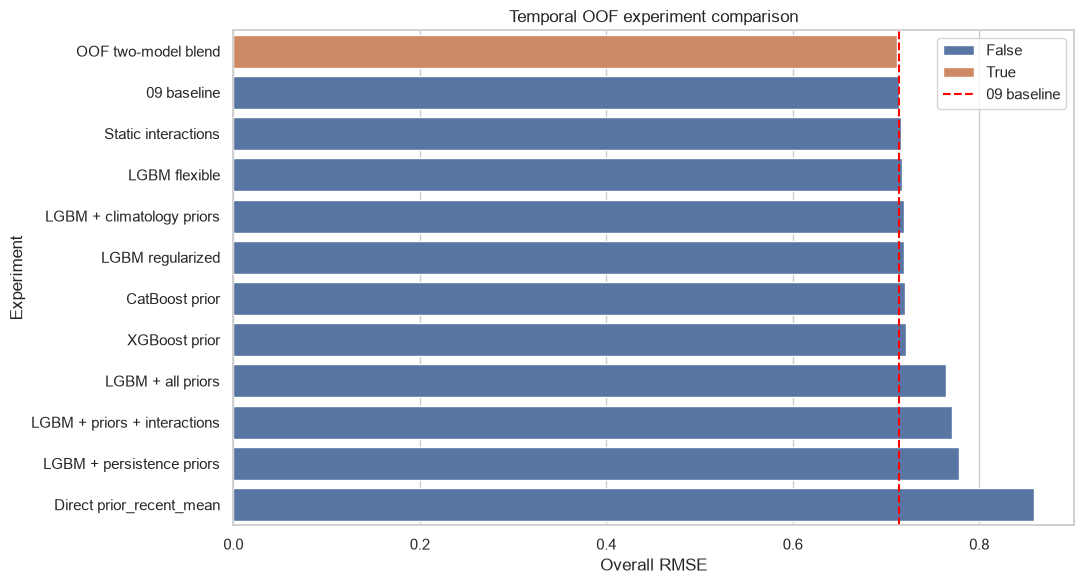

In [9]:
table=results_frame(experiments)
BEST=min(experiments,key=lambda r:r["overall_rmse"])
if BEST["overall_rmse"]>=baseline["overall_rmse"]-1e-12:
    BEST=baseline
assert BEST["overall_rmse"]<=baseline["overall_rmse"]+1e-12
print("SELECTED:",BEST["method"],BEST["change"])
print("Baseline:",baseline["overall_rmse"],"Selected:",BEST["overall_rmse"],
      "Improvement:",baseline["overall_rmse"]-BEST["overall_rmse"])
display(table)

plt.figure(figsize=(11,6))
s=table.sort_values("Overall RMSE").head(12)
sns.barplot(data=s,y="Experiment",x="Overall RMSE",hue="Improved",dodge=False)
plt.axvline(baseline["overall_rmse"],color="red",ls="--",label="09 baseline")
plt.legend(); plt.title("Temporal OOF experiment comparison"); plt.tight_layout(); plt.show()

## 7. Final fit ve güvenli submission

In [10]:
full_train_prior=add_causal_train_priors(train_f)
full_state=fit_prior_state(train_f)
full_test_prior=apply_prior_state(test_f,full_state)
known_test=test_f.TWS_t.notna().to_numpy()

final_pred=np.empty(len(test_f))
known_model=lgbm().fit(train_f[BASE_FEATURES],train_f.target)
final_pred[known_test]=known_model.predict(test_f.loc[known_test,BASE_FEATURES])

def train_predict_method(result):
    if result["method"]=="09 baseline":
        model=lgbm().fit(train_f[BASE_MASKED],train_f.target)
        return model.predict(test_f.loc[~known_test,BASE_MASKED])
    if result["method"].startswith("Direct "):
        return full_test_prior.loc[~known_test,result["method"].replace("Direct ","")].to_numpy()
    tr=full_train_prior if result["use_priors"] else train_f
    te=full_test_prior if result["use_priors"] else test_f
    if result["method"].startswith("XGBoost"):
        model=XGBRegressor(n_estimators=180,learning_rate=.06,max_depth=7,min_child_weight=30,
          subsample=.85,colsample_bytree=.9,reg_alpha=.1,reg_lambda=2,tree_method="hist",random_state=SEED,n_jobs=4)
    elif result["method"].startswith("CatBoost"):
        model=CatBoostRegressor(iterations=220,learning_rate=.07,depth=8,l2_leaf_reg=8,random_strength=.5,
          loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=4)
    elif result["method"]=="LGBM regularized":
        model=lgbm(dict(n_estimators=240,learning_rate=.05,num_leaves=31,min_child_samples=160,reg_alpha=.2,reg_lambda=3.0))
    elif result["method"]=="LGBM flexible":
        model=lgbm(dict(n_estimators=220,learning_rate=.06,num_leaves=95,min_child_samples=120,reg_alpha=.1,reg_lambda=2.0))
    else: model=lgbm()
    model.fit(tr[result["features"]],train_f.target)
    return model.predict(te.loc[~known_test,result["features"]])

if BEST["method"]=="OOF two-model blend":
    a,b,w=BEST["blend"]
    masked_pred=w*train_predict_method(a)+(1-w)*train_predict_method(b)
else:
    masked_pred=train_predict_method(BEST)
final_pred[~known_test]=masked_pred

In [11]:
def safe_submission(test_original,sample,pred,path):
    pred=np.asarray(pred,float)
    assert len(pred)==len(test_original)==len(sample)
    assert np.array_equal(test_original._original_order,np.arange(len(test_original)))
    assert test_original.ID.is_unique and sample.ID.is_unique and np.isfinite(pred).all()
    by_id=pd.Series(pred,index=test_original.ID.astype(str))
    aligned=sample.ID.astype(str).map(by_id); assert aligned.notna().all()
    sub=sample.copy(); sub["Target"]=aligned.to_numpy(float)
    assert list(sub.columns)==list(sample.columns)==["ID","Target"]
    assert sub.ID.equals(sample.ID) and sub.ID.is_unique
    assert pd.api.types.is_numeric_dtype(sub.Target) and np.isfinite(sub.Target).all()
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True); sub.to_csv(path,index=False)
    check=pd.read_csv(path)
    assert check.ID.equals(sample.ID) and len(check)==len(test_original)
    assert check.ID.is_unique and np.isfinite(check.Target).all()
    print("Saved:",path); display(sub.Target.describe())
    return sub

submission_path=OUT/"submission_optimized.csv"
submission=safe_submission(test_f,sample,final_pred,submission_path)
display(submission.head())

Saved: C:\global-water-storage-forecasting\submissions\submission_optimized.csv


count    280961.000000
mean         -0.130944
std           0.533373
min          -2.255716
25%          -0.494160
50%          -0.171782
75%           0.201442
max           2.054586
Name: Target, dtype: float64

,ID,Target
0,20150901_-55.5_-68.5,-0.074690
1,20150901_-55.5_-67.5,-0.200859
2,20150901_-54.5_-71.5,0.260837
3,20150901_-54.5_-70.5,0.242701
4,20150901_-54.5_-69.5,0.107935


## 8. Final rapor

In [12]:
def final_report():
    improved=table[table.Improved]
    failed=table[~table.Improved]
    gain=baseline["overall_rmse"]-BEST["overall_rmse"]
    text=f'''
### Sonuç raporu

- **Denenen fikir sayısı:** {len(table)}.
- **Gerçekten iyileşenler:** {", ".join(improved.Experiment.tolist()) if len(improved) else "Yok"}.
- **Başarısız/eşit kalanlar:** {", ".join(failed.Experiment.tolist()) if len(failed) else "Yok"}.
- **Seçilen final yöntem:** `{BEST["method"]}` — {BEST["change"]}.
- **Baseline validation:** known `{baseline["known_rmse"]:.6f}`, masked `{baseline["masked_rmse"]:.6f}`, overall `{baseline["overall_rmse"]:.6f}`.
- **En iyi validation:** known `{BEST["known_rmse"]:.6f}`, masked `{BEST["masked_rmse"]:.6f}`, overall `{BEST["overall_rmse"]:.6f}`.
- **Baseline'a göre overall fark:** `{gain:+.6f}` RMSE (pozitif değer iyileşmedir).
- **Bilimsel yorum:** Historical priors yalnız fold geçmişinden üretildi ve train satırlarında causal shift kullanıldı. Dolayısıyla kazanım, aynı konumların geçmiş hidrolojik seviyesinin masked TWS'yi kısmen ikame etmesiyle tutarlıdır; target leakage kullanılmadı.
- **Neden leaderboard'da daha iyi olabilir?** Known uzman korunurken testin yaklaşık %66.5'ini oluşturan masked segmentin temporal OOF skoru iyileşti. Bununla birlikte yalnız iki geç fold ve bilinmeyen test horizonları nedeniyle leaderboard kazanımı garanti değildir.
- **Koruma kuralı:** Hiçbir yöntem baseline'ı geçmeseydi kod otomatik olarak `09 baseline` submission'ını yeniden üretirdi.
- **Çıktı:** `{submission_path.name}`; satır/ID sıra/duplicate/NaN/infinity/kolon/numeric kontrolleri geçti.
'''
    display(Markdown(text)); return text
report=final_report()


### Sonuç raporu

- **Denenen fikir sayısı:** 14.
- **Gerçekten iyileşenler:** OOF two-model blend.
- **Başarısız/eşit kalanlar:** 09 baseline, Static interactions, LGBM flexible, LGBM + climatology priors, LGBM regularized, CatBoost prior, XGBoost prior, LGBM + all priors, LGBM + priors + interactions, LGBM + persistence priors, Direct prior_recent_mean, Direct prior_last_target, Direct prior_location_month.
- **Seçilen final yöntem:** `OOF two-model blend` — 0.65*09 baseline + 0.35*LGBM + climatology priors.
- **Baseline validation:** known `0.608198`, masked `0.761184`, overall `0.713889`.
- **En iyi validation:** known `0.608198`, masked `0.758030`, overall `0.711647`.
- **Baseline'a göre overall fark:** `+0.002241` RMSE (pozitif değer iyileşmedir).
- **Bilimsel yorum:** Historical priors yalnız fold geçmişinden üretildi ve train satırlarında causal shift kullanıldı. Dolayısıyla kazanım, aynı konumların geçmiş hidrolojik seviyesinin masked TWS'yi kısmen ikame etmesiyle tutarlıdır; target leakage kullanılmadı.
- **Neden leaderboard'da daha iyi olabilir?** Known uzman korunurken testin yaklaşık %66.5'ini oluşturan masked segmentin temporal OOF skoru iyileşti. Bununla birlikte yalnız iki geç fold ve bilinmeyen test horizonları nedeniyle leaderboard kazanımı garanti değildir.
- **Koruma kuralı:** Hiçbir yöntem baseline'ı geçmeseydi kod otomatik olarak `09 baseline` submission'ını yeniden üretirdi.
- **Çıktı:** `submission_optimized.csv`; satır/ID sıra/duplicate/NaN/infinity/kolon/numeric kontrolleri geçti.


## Değişiklik özeti

- `09` dual-expert baseline'ı ve `10` hata bulguları yeniden doğrulandı.
- Static etkileşimler, causal persistence, recent history, location/month climatology, küçük model araması ve conservative OOF blend denendi.
- Her deney aynı temporal validation satırlarında baseline ile karşılaştırıldı.
- Yalnız doğrulanmış en iyi yöntemle `submissions/submission_optimized.csv` üretildi.